# **SIFT Algorithm**

SIFT (Scale Invariant Feature Transform) is a widely used feature detection and description algorithm in computer vision.

The algorithm can be divided into several steps:

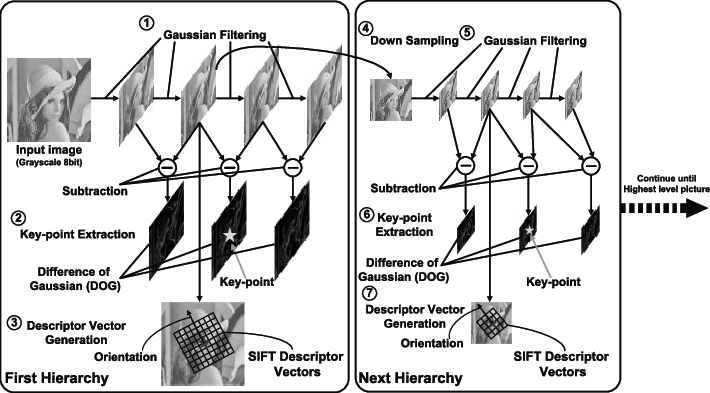

"A Low-Power Real-Time SIFT Descriptor Generation Engine for Full-HDTV Video Recognition", Mizuno et al., IEICE Transactions on Electronics, 2011.


We will use the OpenCV implementation of the SIFT algorithm to detect keypoints and descriptors of an image.

In [3]:
# Update OpenCV package
!pip install -U opencv-python
!pip install -U scikit-learn

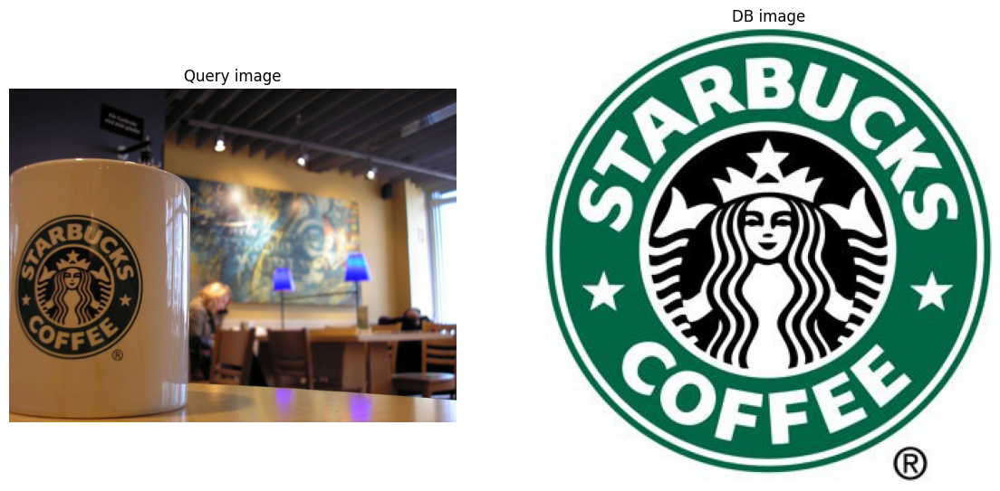

In [ ]:
# Import libraries
import cv2
import matplotlib.pyplot as plt
import numpy as np
import sklearn.metrics

# Read images
db_image = cv2.imread("db.jpg")
db_image = cv2.cvtColor(db_image, cv2.COLOR_BGR2RGB) #conversion en RGB
query_image = cv2.imread("query.jpg")
query_image = cv2.cvtColor(query_image, cv2.COLOR_BGR2RGB) #conversion en RGB

# Display images
fig = plt.figure(figsize=(14, 12))
plt.subplot(1,2,1), plt.imshow(query_image), plt.title("Query image"), plt.axis("off")
plt.subplot(1,2,2), plt.imshow(db_image), plt.title("DB image"), plt.axis("off")
plt.show()

In [ ]:
# Define SIFT detector
# SIFT_create([, nfeatures[, nOctaveLayers[, contrastThreshold[, edgeThreshold[, sigma]]]]]) -> retval
sift = cv2.SIFT_create() #crée un objet SIFT

# Detects keypoints and computes the descriptors
# keypoints, descriptors	=	cv2.Feature2D.detectAndCompute(	image, mask[, descriptors[, useProvidedKeypoints]]	)
keypoints_q, descriptors_q = sift.detectAndCompute(query_image, None) #détecte les points intéressants et calcule les signatures numériques de chaque keypoint

#keypoints_q = liste des points intéressants détectés dans l'image
#descriptors_q = matrice contenant les signatures numériques calculées pour les points intéressants 

# Print number of keypoints
print(f"Number of detected keypoints/descriptors (Query image): {len(keypoints_q)}")
keypoints_db, descriptors_db = sift.detectAndCompute(db_image, None)
# Print number of keypoints
print(f"Number of detected keypoints/descriptors (Database image): {len(keypoints_db)}")

Number of detected keypoints/descriptors (Query image): 1033
Number of detected keypoints/descriptors (Database image): 565


In [6]:
# Select 1st keypoint and show (some of) its attributes
kpt = keypoints_q[0]
des = descriptors_q[0]
print(f"\n1st Keypoint Attributes\n")
print(f"Class: {type(kpt)}")
print(f"Angle (computed orientation of the keypoint): {kpt.angle}")
print(f"Pt (coordinates of the keypoint): {kpt.pt}")
print(f"Response ('strength' of the keypoint): {kpt.response}")
print(f"Size (diameter of the meaningful keypoint neighborhood): {kpt.size}")
print(f"Descriptor Length: {des.size}:\n")
print(f"Descriptor: \n{des}")


1st Keypoint Attributes

Class: <class 'cv2.KeyPoint'>
Angle (computed orientation of the keypoint): 175.98544311523438
Pt (coordinates of the keypoint): (3.2508511543273926, 209.72352600097656)
Response ('strength' of the keypoint): 0.015537815168499947
Size (diameter of the meaningful keypoint neighborhood): 2.5997893810272217
Descriptor Length: 128:

Descriptor: 
[138.  13.   1.   0.   0.   0.   0.   6.  33.  19.   5.   1.   2.   7.
  18.  43.   2.   0.   0.   1.  21.  68.  27.  15.   0.   0.   0.   0.
   3.   6.   0.   0. 138.  25.   0.   0.   0.   0.   0.  18. 138.  36.
   5.   5.   5.  26.  53. 138.  28.   9.   8.  39.  92. 138.  76.  58.
   0.   0.   0.   2.   8.  21.   1.   0.  96.  82.   0.   0.   0.   0.
   0.   1. 138. 138. 107.  31.   3.   3.   2.  13.  22.  46. 138. 138.
  58.  23.   2.   5.   0.   0.   6.  12.   4.   2.   0.   0.  65.  54.
   0.   0.   0.   0.   0.   0.  23.  65.  42.  14.   2.   1.   0.   1.
   0.   4.  52.  50.   8.   3.   1.   0.   0.   0.   2.   2.  

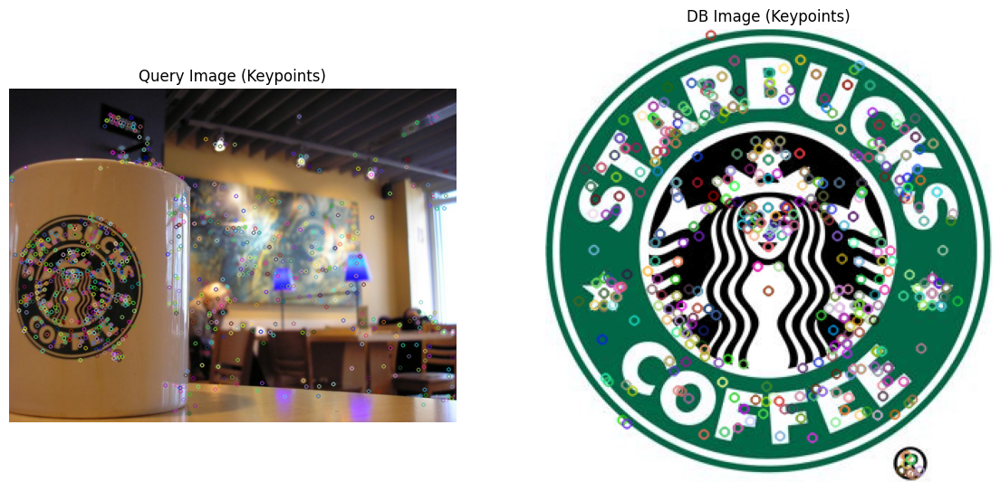

In [11]:
# Copy images
q_img = query_image.copy() #on copie les images pour ne pas sans modifier les images originales
db_img = db_image.copy()

# Draw keypoints of the original image
# outImage	=	cv2.drawKeypoints(	image, keypoints, outImage[, color[, flags]]	)
cv2.drawKeypoints(q_img, keypoints_q, q_img, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_OVER_OUTIMG) #image sur laquelle dessiner, keypoints à prendre, image de sortie
                                        #cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS --> plus de détails sur l'image (échelle du point, orientation)
cv2.drawKeypoints(db_img, keypoints_db, db_img, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_OVER_OUTIMG) #flags indique qu'on dessine par-dessus l'image
# Display image with keypoints
plt.figure(figsize=(14, 8)),
plt.subplot(1,2,1), plt.imshow(q_img), plt.title("Query Image (Keypoints)"), plt.axis("off")
plt.subplot(1,2,2), plt.imshow(db_img), plt.title("DB Image (Keypoints)"),  plt.axis("off")
plt.show()

# **Feature Matching**

Feature matching is a computer vision technique for establishing correspondences between two images containing the same (or similar) elements. The general idea is to match keypoints (and descriptors) of a query image to the most similar keypoints (and descriptors) of a database image. They can be obtained with a brute-force or an approximate (FLANN) search, keeping either the single best match or the k best ones (k-NN).


## **Brute-Force (BF) Matcher**

*BF Matcher* finds, for each descriptor, of the query image the closest descriptor (using Euclidean distance or another distance measure) of the database image. In other words, for each descriptor of the query image, it computes the distance between this descriptor and all the descriptors detected in the database image. Then, the closest database descriptor is selected and associated with the query descriptor. Once all the correspondences have been found, matches whose distances are greater than a fixed threshold are removed to only consider "robust" matches.

Note that this matching procedure can be very slow if the number of detected features is high.

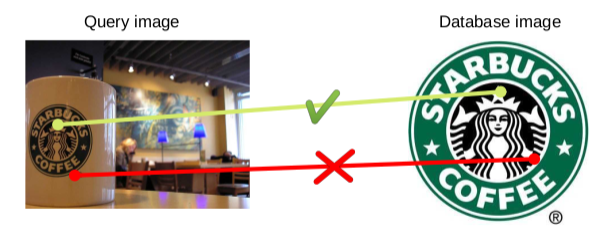

To start, we extract keypoints and descriptors for both the query and database images.


In [13]:
# Detect and compute keypoints and descriptors
query_keypoints, query_descriptors = sift.detectAndCompute(query_image, None)
db_keypoints, db_descriptors = sift.detectAndCompute(db_image, None)
print(f"\nNumber of keypoints (query image): {len(query_keypoints)}.")
print(f"Number of keypoints (database image): {len(db_keypoints)}.\n")


Number of keypoints (query image): 1033.
Number of keypoints (database image): 565.



**With Numpy**: we create a distance matrix and compute the Euclidean distance between each query descriptor and all the database descriptors. The rows should correspond to the query descriptors while the columns to the database descriptors.

In [16]:
# Distance matrix (rows correspond to query descriptors while columns to database descriptors)
dist_matrix = np.zeros((len(query_descriptors), len(db_descriptors))) #on crée une matrice de 0 de taille nb descripteurs image requête x image db
for i, desQ in enumerate(query_descriptors): #on parcoure tout les descripteurs de l'image requête et l'image db
  for j, desD in enumerate(db_descriptors):
    dist_matrix[i, j] = np.linalg.norm(desQ-desD) #distance euclidienne entre les 2 points

# Find the closest database descriptor for each query descriptor
# and the corresponding distance
min_distances = dist_matrix.min(axis = 1) #on trouve le minimum pour chaque descripteur (axis=1 : on cherche le résultat minimal par lignes, ≠ colonnes)
db_descriptors_idx = np.argmin(dist_matrix, axis=1) #np.argmin renvoie l'indice où se trouve la distance min dans chaque ligne

# print info
print("Number of matches", min_distances.shape) #résultat de 1033 parce qu'on a un résultat minimal par descripteur de l'image de requête

Number of matches (1033,)


OpenCV provides a method, "BFMatcher_create()", that implements the Brute-Force matcher.

In [ ]:
# Brute-force matcher create method.
# retval	=	cv.BFMatcher_create([, normType[, crossCheck]])
bf = cv2.BFMatcher_create(cv2.NORM_L2) #utilise la distance euclidienne pour comparer les descripteurs

# Finds the best match for each descriptor from a query set.
# matches	=	cv.DescriptorMatcher.match(	queryDescriptors, trainDescriptors[, mask]	)
# It returns a list of DMatch objects with the following attributes:
# DMatch.distance - Distance between descriptors. The lower, the better it is.
# DMatch.trainIdx - Index of the descriptor in train descriptors
# DMatch.queryIdx - Index of the descriptor in query descriptors
matches = bf.match(query_descriptors, db_descriptors)

# print info
print("Number of matches:", len(matches))

print('DMatch object attributes (matches[0]):')
print(f'DMatch.distance: {matches[0].distance}') #distance euclidienne du 1er descripteur
print(f'DMatch.queryIdx: {matches[0].queryIdx}') #index du 1er descripteur
print(f'DMatch.trainIdx: {matches[0].trainIdx}') #index du descripteur correspondant dans db_descriptors (image db)

Number of matches: 1033
DMatch object attributes (matches[0]):
DMatch.distance: 429.7429504394531
DMatch.queryIdx: 0
DMatch.trainIdx: 500


Let's visualize the matches.

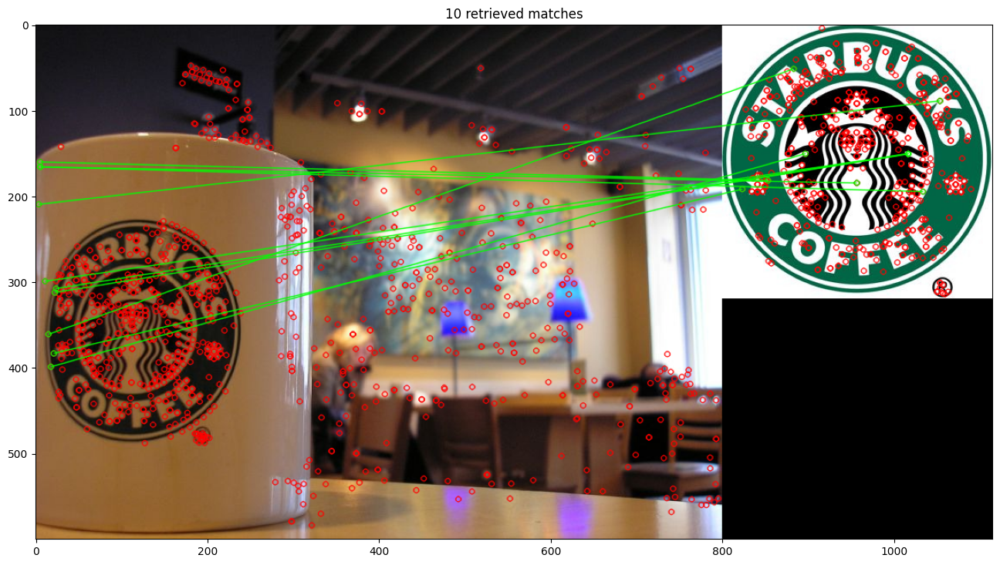

In [23]:
# Plot 10 retrieved matches
# outImg	=	cv.drawMatches(img1, keypoints1, img2, keypoints2, matches1to2, outImg[, matchColor[, singlePointColor[, matchesMask[, flags]]]]	)
draw_params = dict(matchColor=(0, 255, 0), singlePointColor=(255, 0, 0), flags=0) #paramètres de dessin
img_matches = cv2.drawMatches(query_image, query_keypoints, db_image, db_keypoints, matches[:10], None, **draw_params)

plt.figure(figsize=(16, 16)), plt.imshow(img_matches), plt.title('10 retrieved matches')
plt.show()

In [ ]:
# Discard matches above the threshold
def set_matches_threshold(matches, thrs, print_info=False):
  min_distances_opencv = np.asarray([matches[idx].distance for idx in range(len(matches))]) #rassemble toutes les distances de tout les matches dans un array np
  min_query_descriptors_idx = np.where(min_distances_opencv <= thrs)[0] #on ne garde que les distances en dessous du seuil
  min_db_descriptors_idx = np.asarray([matches[idx].trainIdx for idx in min_query_descriptors_idx]) #récupérer les indices correspondants dans db
  if print_info:
    print(f"\nNumber of matches: {len(min_query_descriptors_idx)}")
    # Print Euclidean distance, query descriptor index and database descriptor index of retrieved matches
    for idx in range(15):
      query_idx = min_query_descriptors_idx[idx]
      print(f"Euclidean distance: {min_distances_opencv[query_idx]:.2f}, Query Descriptor: n. {query_idx}, Database Descriptor: n.{min_db_descriptors_idx[idx]}")
    print("Output truncated at 15 matches")
  return min_query_descriptors_idx, min_db_descriptors_idx

In [25]:
# Check the compatibility between the two methods
thrs = 100
min_query_descriptors_idx, min_db_descriptors_idx = set_matches_threshold(matches, thrs, print_info=True)


Number of matches: 105
Euclidean distance: 84.73, Query Descriptor: n. 143, Database Descriptor: n.176
Euclidean distance: 86.87, Query Descriptor: n. 149, Database Descriptor: n.190
Euclidean distance: 84.30, Query Descriptor: n. 157, Database Descriptor: n.196
Euclidean distance: 77.37, Query Descriptor: n. 163, Database Descriptor: n.206
Euclidean distance: 61.28, Query Descriptor: n. 184, Database Descriptor: n.212
Euclidean distance: 86.45, Query Descriptor: n. 192, Database Descriptor: n.318
Euclidean distance: 94.24, Query Descriptor: n. 195, Database Descriptor: n.237
Euclidean distance: 83.38, Query Descriptor: n. 198, Database Descriptor: n.235
Euclidean distance: 79.15, Query Descriptor: n. 199, Database Descriptor: n.236
Euclidean distance: 60.12, Query Descriptor: n. 205, Database Descriptor: n.253
Euclidean distance: 79.21, Query Descriptor: n. 207, Database Descriptor: n.246
Euclidean distance: 76.26, Query Descriptor: n. 208, Database Descriptor: n.247
Euclidean distan

# STOPPED HERE

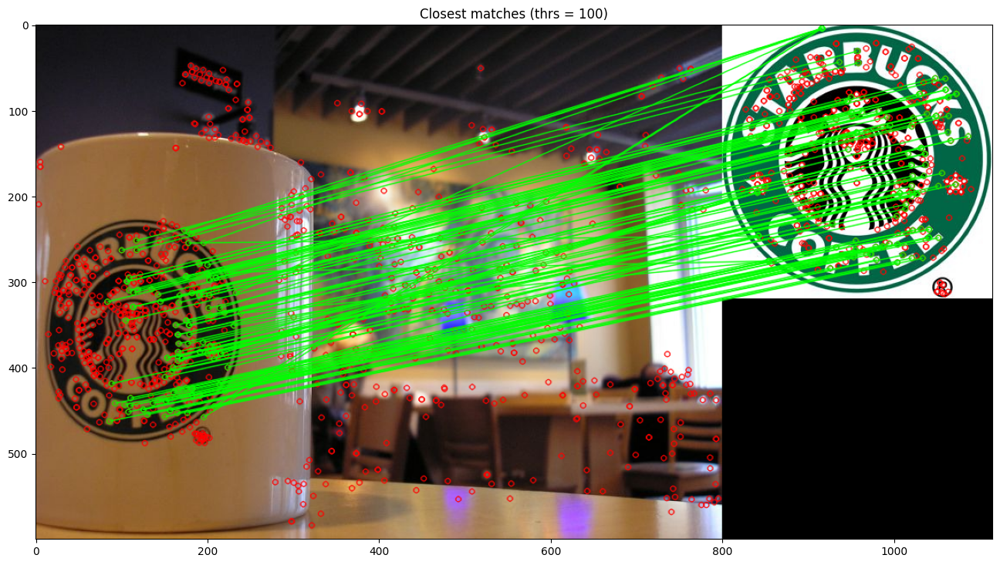

In [ ]:
# Plot the closest matches (distance <= thrs)
# outImg	=	cv.drawMatches(img1, keypoints1, img2, keypoints2, matches1to2, outImg[, matchColor[, singlePointColor[, matchesMask[, flags]]]]	)
draw_params = dict(matchColor=(0, 255, 0), singlePointColor=(255, 0, 0), flags=0)
closest_matches = [matches[idx] for idx in min_query_descriptors_idx]
img_matches = cv2.drawMatches(query_image, query_keypoints, db_image, db_keypoints, closest_matches, None, **draw_params)

plt.figure(figsize=(16, 16)), plt.imshow(img_matches), plt.title(f'Closest matches (thrs = {thrs})')
plt.show()

We observe that the chosen threshold value is too high, since several matches are wrong.

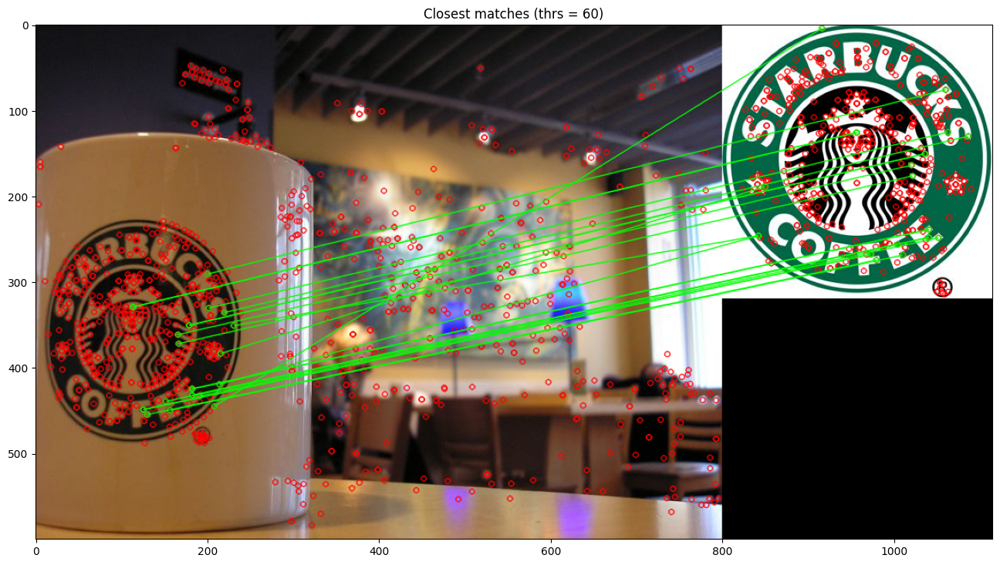

In [ ]:
# let's try with a smaller threshold
thrs = 60
min_query_descriptors_idx, min_db_descriptors_idx = set_matches_threshold(matches, thrs)
draw_params = dict(matchColor=(0, 255, 0), singlePointColor=(255, 0, 0), flags=0)
closest_matches = [matches[idx] for idx in min_query_descriptors_idx]
img_matches = cv2.drawMatches(query_image, query_keypoints, db_image, db_keypoints, closest_matches, None, **draw_params)

plt.figure(figsize=(16, 16)), plt.imshow(img_matches), plt.title(f'Closest matches (thrs = {thrs})')
plt.show()

Now the matches seem good, but is this threshold generalizable?

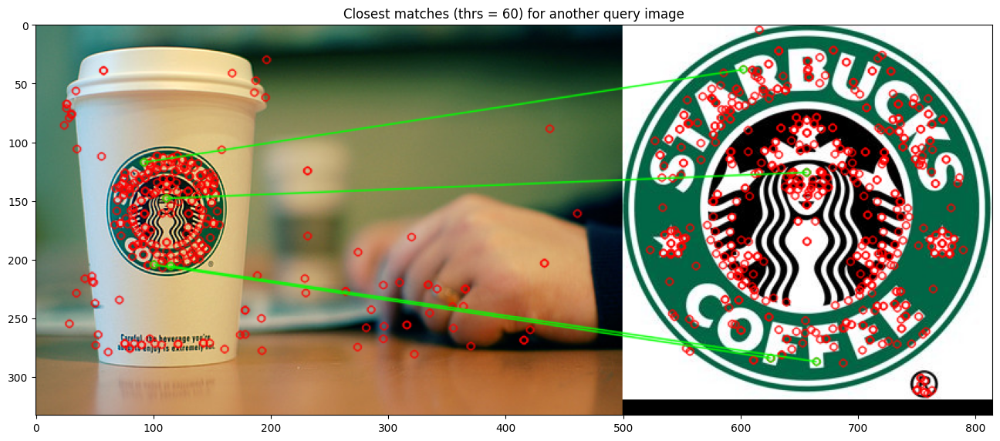

In [ ]:
# Let's apply the brute-force matcher with the same threshold value to a different query image
query_image2 = cv2.imread("query_2.jpg")
query_image2 = cv2.cvtColor(query_image2, cv2.COLOR_BGR2RGB)
query_keypoints2, query_descriptors2 = sift.detectAndCompute(query_image2, None)
bf = cv2.BFMatcher_create(cv2.NORM_L2)
matches2 = bf.match(query_descriptors2, db_descriptors)
thrs = 60
min_query_descriptors_idx, min_db_descriptors_idx = set_matches_threshold(matches2, thrs)
draw_params = dict(matchColor=(0, 255, 0), singlePointColor=(255, 0, 0), flags=0)
closest_matches = [matches2[idx] for idx in min_query_descriptors_idx]
img_matches = cv2.drawMatches(query_image2, query_keypoints2, db_image, db_keypoints, closest_matches, None, **draw_params)

plt.figure(figsize=(16, 16)), plt.imshow(img_matches), plt.title(f'Closest matches (thrs = {thrs}) for another query image')
plt.show()

For this new image, the previous threshold is too severe: let's try to increase it to get more correct matches.

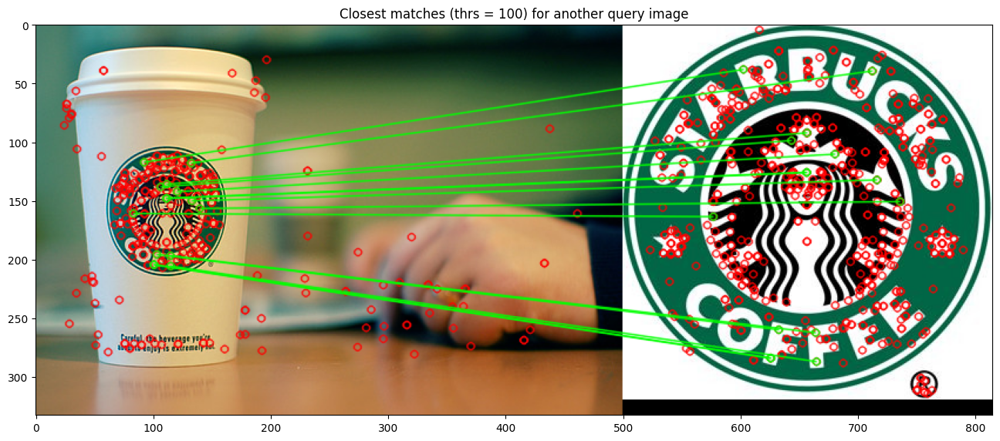

In [ ]:
thrs = 100
min_query_descriptors_idx, min_db_descriptors_idx = set_matches_threshold(matches2, thrs)
draw_params = dict(matchColor=(0, 255, 0), singlePointColor=(255, 0, 0), flags=0)
closest_matches = sorted([matches2[idx] for idx in min_query_descriptors_idx], key = lambda m:m.distance)
img_matches = cv2.drawMatches(query_image2, query_keypoints2, db_image, db_keypoints, closest_matches[:15], None, **draw_params)

plt.figure(figsize=(16, 16)), plt.imshow(img_matches), plt.title(f'Closest matches (thrs = {thrs}) for another query image')
plt.show()

What if we don't want to fine-tune the value of the threshold for each query image?

## **Ex. 1.a - Ratio test**

> In this exercise, you will implement a K-NN matcher to get the K best matches (rather than the closest one). We set $k=2$ in order to apply the ratio test as reported by D. Lowe [[Ref]](https://www.cs.ubc.ca/~lowe/papers/ijcv04.pdf).

Consider the following steps:

*   Apply the SIFT algorithm to detect keypoints and descriptors of query and database images.
*   For each query descriptor ($des_{q_i}$), you need to find the closest ($des_{db_j}$) and the second closest ($des_{db_k}$) database descriptors.
*   Then, apply the ratio test to check if there is a match between $des_{q_i}$ and $des_{db_j}$. The ratio test is defined as follows:

\begin{equation}
\frac{dist(i,j)}{dist(i,k)} \lt 0.70
\end{equation}

where $dist(i,j) = ||(des_{q_i}-des_{db_j})||_2$ and $dist(i,k) = ||(des_{q_i}-des_{db_k})||_2$.

 If the above condition is satisfied, $des_{q_i}$ is matched to $des_{db_j}$. If the above condition is not satisfied, $des_{q_i}$ cannot be matched to any database descriptor.

In [ ]:
# Detect and compute keypoints and descriptors
# keypoints, descriptors	=	cv2.Feature2D.detectAndCompute(	image, mask[, descriptors[, useProvidedKeypoints]]	)
query_keypoints, query_descriptors = sift.detectAndCompute(query_image, None)
db_keypoints, db_descriptors = sift.detectAndCompute(db_image, None)
print(f"Query image descriptors shape: {query_descriptors.shape}, database image descriptors shape: {db_descriptors.shape}")

Query image descriptors shape: (1033, 128), database image descriptors shape: (565, 128)


In [ ]:
%%time
# Pairwise distances between query and database descriptors
# YOUR CODE
print(f"Distance matrix shape: {dist_matrix.shape}")

## K-NN matcher (K=2)
# For each query img descriptor find the distances and indices (db_idx) of the 2 closest database img descriptors.
k = 2
# YOUR CODE
print(f"Distance matrix of each query image descriptor and its 2 closest database image descriptors: {distances.shape}")

Distance matrix shape: (1033, 565)
Distance matrix of each query image descriptor and its 2 closest database image descriptors: (1033, 2)
CPU times: user 165 ms, sys: 7.91 ms, total: 173 ms
Wall time: 277 ms


In [ ]:
# Implement ratio test using distances and db_idx
min_dist = [] # dist(i,j) that pass the test
min_query_idx = [] # indices of the query descriptors that pass the test
min_db_idx = [] # indices of the database descriptors that pass the test

# YOUR CODE

In [ ]:
# Print some info
print(f"Number of query keypoints: {len(query_keypoints)}")
print(f"Number of database keypoints: {len(db_keypoints)}")
print(f"Number of matches: {len(min_query_idx)}")

Number of query keypoints: 1033
Number of database keypoints: 565
Number of matches: 203


In [ ]:
# Print first 10 retrieved matches
nMatches = 10
for k in range(nMatches):
  print(f"Euclidean distance: {min_dist[k]:.2f}, Query Descriptor: n. {min_query_idx[k]}, Database Descriptor: n.{min_db_idx[k]}")

Euclidean distance: 182.84, Query Descriptor: n. 18, Database Descriptor: n.4
Euclidean distance: 195.76, Query Descriptor: n. 20, Database Descriptor: n.3
Euclidean distance: 167.45, Query Descriptor: n. 32, Database Descriptor: n.12
Euclidean distance: 146.96, Query Descriptor: n. 42, Database Descriptor: n.31
Euclidean distance: 231.46, Query Descriptor: n. 43, Database Descriptor: n.32
Euclidean distance: 199.72, Query Descriptor: n. 44, Database Descriptor: n.36
Euclidean distance: 178.87, Query Descriptor: n. 45, Database Descriptor: n.41
Euclidean distance: 175.91, Query Descriptor: n. 46, Database Descriptor: n.42
Euclidean distance: 199.60, Query Descriptor: n. 48, Database Descriptor: n.43
Euclidean distance: 203.06, Query Descriptor: n. 50, Database Descriptor: n.509


> OpenCV provides the knnMatch() function which implements the k-NN matcher.

In [ ]:
# Create BFMatcher
bf = cv2.BFMatcher_create(cv2.NORM_L2)

# Apply k-NN match
# Finds the k best matches for each descriptor from a query set.
# matches	=	cv.DescriptorMatcher.knnMatch(	queryDescriptors, trainDescriptors, k[, mask[, compactResult]]	)
matches = bf.knnMatch(query_descriptors, db_descriptors, k=2) #  num_query_descriptors -> [2]

# Build ratio test function
def ratio_test(matches, ratio=0.7):
  matched_des = []
  for m_ij, m_ik in matches:
      if m_ij.distance < ratio * m_ik.distance:
          matched_des.append(m_ij)
  return matched_des

matched_des = ratio_test(matches)

In [ ]:
print(f"Number of matches: {len(matched_des)}")

Number of matches: 203


In [ ]:
nMatches = 10
for k in range(nMatches):
  print(f"Euclidean distance: {matched_des[k].distance:.2f}, Query Descriptor: n. {matched_des[k].queryIdx}, Database Descriptor: n.{matched_des[k].trainIdx}")

Euclidean distance: 182.84, Query Descriptor: n. 18, Database Descriptor: n.4
Euclidean distance: 195.76, Query Descriptor: n. 20, Database Descriptor: n.3
Euclidean distance: 167.45, Query Descriptor: n. 32, Database Descriptor: n.12
Euclidean distance: 146.96, Query Descriptor: n. 42, Database Descriptor: n.31
Euclidean distance: 231.46, Query Descriptor: n. 43, Database Descriptor: n.32
Euclidean distance: 199.72, Query Descriptor: n. 44, Database Descriptor: n.36
Euclidean distance: 178.87, Query Descriptor: n. 45, Database Descriptor: n.41
Euclidean distance: 175.91, Query Descriptor: n. 46, Database Descriptor: n.42
Euclidean distance: 199.60, Query Descriptor: n. 48, Database Descriptor: n.43
Euclidean distance: 203.06, Query Descriptor: n. 50, Database Descriptor: n.509


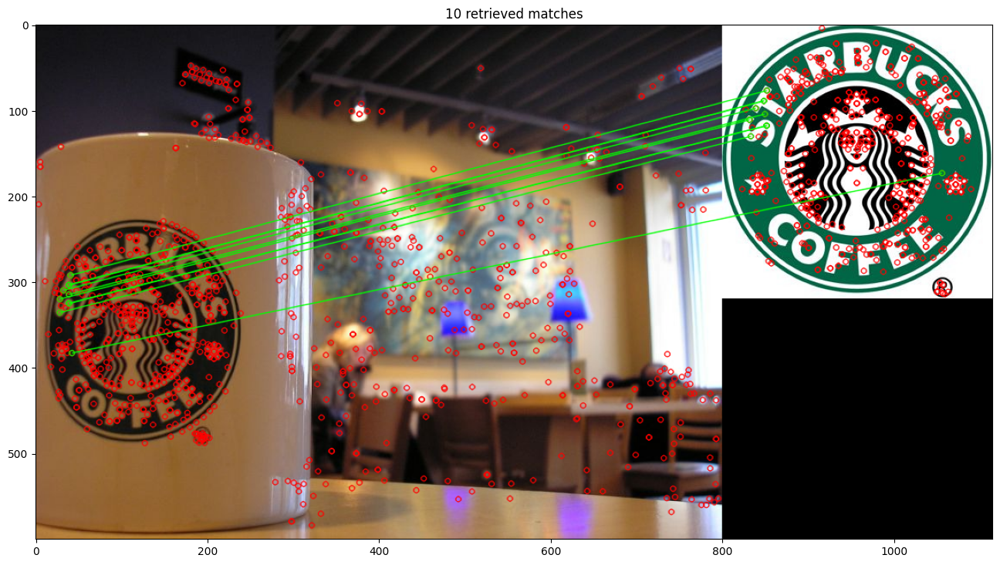

In [ ]:
# Plot 10 retrieved matches
draw_params = dict(matchColor=(0, 255, 0), singlePointColor=(255, 0, 0), flags=0)
img_matches = cv2.drawMatches(query_image, query_keypoints, db_image, db_keypoints, matched_des[:10], None, **draw_params)
plt.figure(figsize=(16, 16)), plt.imshow(img_matches), plt.title('10 retrieved matches')
plt.show()

In [ ]:
# Get ordered matches
ordered_matches = sorted(matched_des, key = lambda m:m.distance)

for k in range(nMatches):
  print(f"Euclidean distance: {ordered_matches[k].distance:.2f}, Query Descriptor: n. {ordered_matches[k].queryIdx}, Database Descriptor: n.{ordered_matches[k].trainIdx}")

Euclidean distance: 27.20, Query Descriptor: n. 466, Database Descriptor: n.495
Euclidean distance: 37.70, Query Descriptor: n. 262, Database Descriptor: n.310
Euclidean distance: 38.91, Query Descriptor: n. 420, Database Descriptor: n.462
Euclidean distance: 41.77, Query Descriptor: n. 492, Database Descriptor: n.516
Euclidean distance: 45.98, Query Descriptor: n. 435, Database Descriptor: n.479
Euclidean distance: 46.13, Query Descriptor: n. 434, Database Descriptor: n.478
Euclidean distance: 48.27, Query Descriptor: n. 437, Database Descriptor: n.477
Euclidean distance: 50.12, Query Descriptor: n. 383, Database Descriptor: n.410
Euclidean distance: 52.06, Query Descriptor: n. 228, Database Descriptor: n.257
Euclidean distance: 52.77, Query Descriptor: n. 387, Database Descriptor: n.420


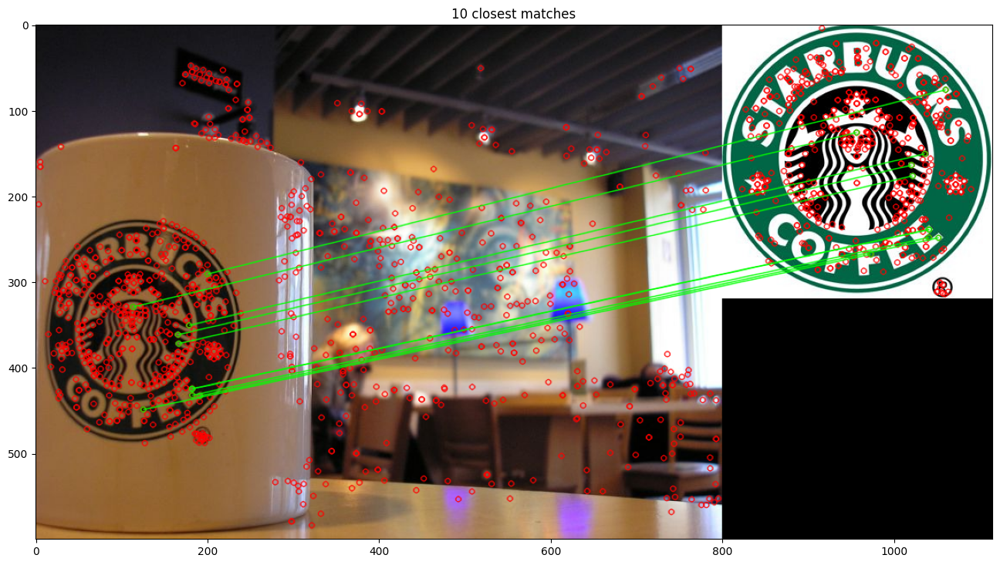

In [ ]:
# Plot 10 closest matches
draw_params = dict(matchColor=(0, 255, 0), singlePointColor=(255, 0, 0), flags=0)
img_matches = cv2.drawMatches(query_image, query_keypoints, db_image, db_keypoints, ordered_matches[:10], None, **draw_params)
plt.figure(figsize=(16, 16)), plt.imshow(img_matches), plt.title('10 closest matches')
plt.show()

Let's try now with the other query image

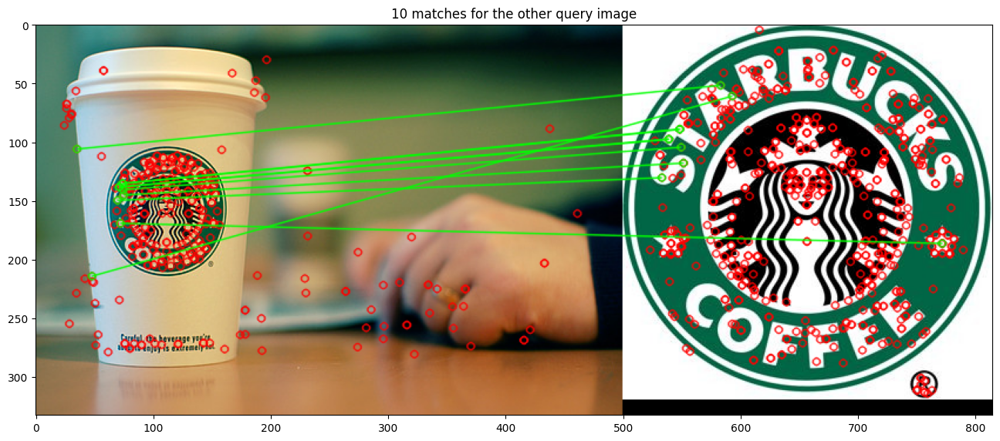

In [ ]:
bf = cv2.BFMatcher_create(cv2.NORM_L2)
matches2 = bf.knnMatch(query_descriptors2, db_descriptors, k=2)
matched_des2 = ratio_test(matches2)
draw_params = dict(matchColor=(0, 255, 0), singlePointColor=(255, 0, 0), flags=0)
img_matches2 = cv2.drawMatches(query_image2, query_keypoints2, db_image, db_keypoints, matched_des2[:10], None, **draw_params)
plt.figure(figsize=(16, 16)), plt.imshow(img_matches2), plt.title('10 matches for the other query image')
plt.show()

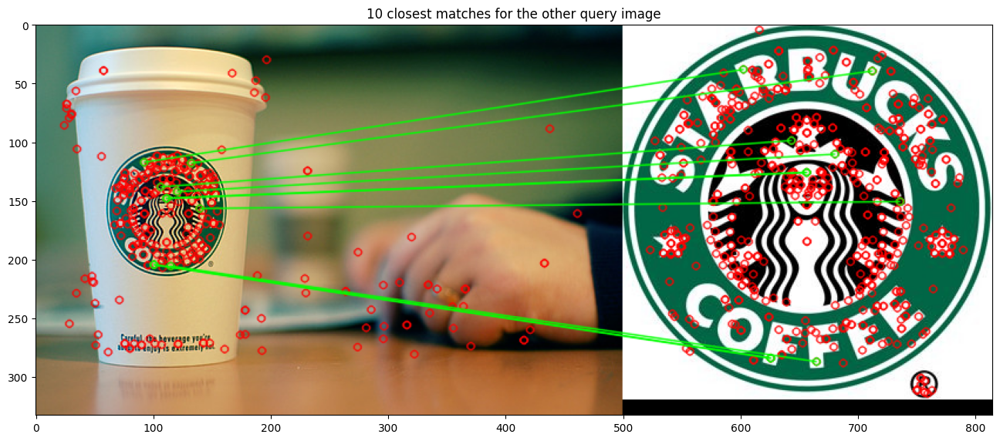

In [ ]:
bf = cv2.BFMatcher_create(cv2.NORM_L2)
matches2 = bf.knnMatch(query_descriptors2, db_descriptors, k=2)
matched_des2 = ratio_test(matches2)
ordered_matches2 = sorted(matched_des2, key = lambda m:m.distance)
draw_params = dict(matchColor=(0, 255, 0), singlePointColor=(255, 0, 0), flags=0)
img_matches2 = cv2.drawMatches(query_image2, query_keypoints2, db_image, db_keypoints, ordered_matches2[:10], None, **draw_params)
plt.figure(figsize=(16, 16)), plt.imshow(img_matches2), plt.title('10 closest matches for the other query image')
plt.show()

## **Ex. 1.b - Change the constant parameter $r$ (0.70) in the ratio test.**
Can you find a better $r$ value for both images?


What happens if $r \rightarrow 1$? What happens if $r \rightarrow 0$?





## **FLANN-based matcher**

Fast Library for Approximate Nearest Neighbors (FLANN) contains a set of optimized algorithms for fast nearest neighbor search in large datasets and it is faster than the Brute-Force matcher.

In [ ]:
%%time
# We need to pass two dictionaries which specify the algorithm to be used and other parameters
FLANN_INDEX_KDTREE = 1
index_params = dict(algorithm = FLANN_INDEX_KDTREE, trees = 5)
# Specify the number of leaves visited / candidates examined
search_params = dict(checks=50)

#	<FlannBasedMatcher object>	=	cv2.FlannBasedMatcher(	[, indexParams[, searchParams]]	)
flann = cv2.FlannBasedMatcher(index_params, search_params)

# Finds the k best matches for each descriptor from a query set.
matches = flann.knnMatch(query_descriptors, db_descriptors, k=2)

CPU times: user 40.6 ms, sys: 1.91 ms, total: 42.5 ms
Wall time: 55.2 ms


In [ ]:
# Apply ratio test
matched_des = ratio_test(matches)

print(f"Number of matches: {len(matched_des)}")

nMatches = 10
for k in range(nMatches):
  print(f"Euclidean distance: {matched_des[k].distance:.2f}, Query Descriptor: n. {matched_des[k].queryIdx}, Database Descriptor: n.{matched_des[k].trainIdx}")

Number of matches: 203
Euclidean distance: 182.84, Query Descriptor: n. 18, Database Descriptor: n.4
Euclidean distance: 195.76, Query Descriptor: n. 20, Database Descriptor: n.3
Euclidean distance: 167.45, Query Descriptor: n. 32, Database Descriptor: n.12
Euclidean distance: 146.96, Query Descriptor: n. 42, Database Descriptor: n.31
Euclidean distance: 231.46, Query Descriptor: n. 43, Database Descriptor: n.32
Euclidean distance: 199.72, Query Descriptor: n. 44, Database Descriptor: n.36
Euclidean distance: 178.87, Query Descriptor: n. 45, Database Descriptor: n.41
Euclidean distance: 175.91, Query Descriptor: n. 46, Database Descriptor: n.42
Euclidean distance: 199.60, Query Descriptor: n. 48, Database Descriptor: n.43
Euclidean distance: 203.06, Query Descriptor: n. 50, Database Descriptor: n.509


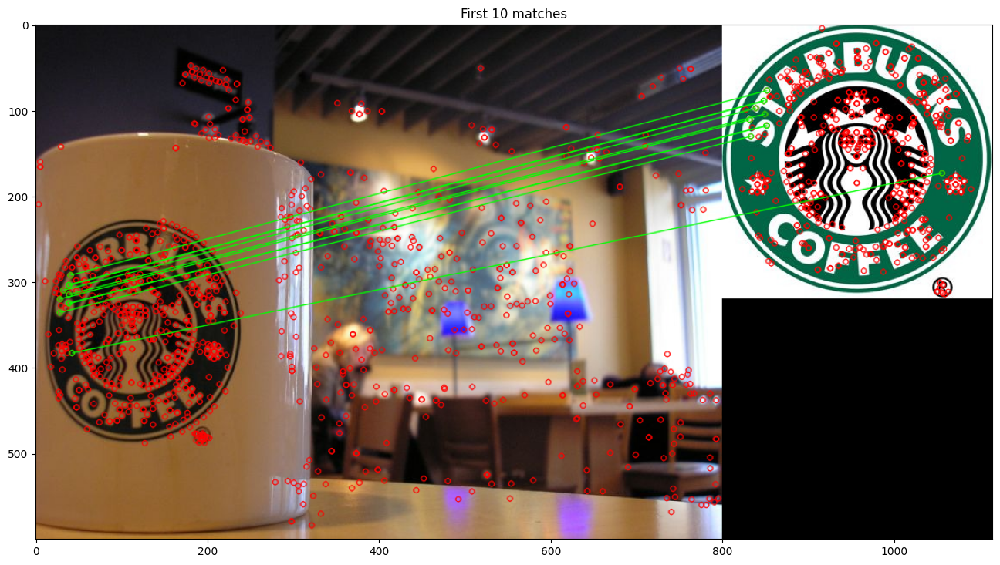

In [ ]:
# Plot
draw_params = dict(matchColor=(0, 255, 0), singlePointColor=(255, 0, 0), flags=0)
img_matches = cv2.drawMatches(query_image, query_keypoints, db_image, db_keypoints, matched_des[:10], None, **draw_params)
plt.figure(figsize=(16, 16)), plt.imshow(img_matches), plt.title('First 10 matches')
plt.show()

# **SIFT Application - Panorama stitching**

Given two images, we will “stitch” them together to create a simple panorama. Both images need to share some common regions.

The example can also be extended to multiple images.

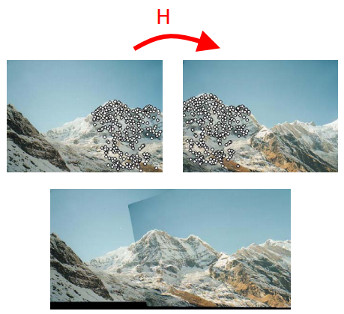

Our panorama stitching algorithm consists of four steps.

**Step 1**: Detect keypoints and extract local invariant descriptors from the two input images.

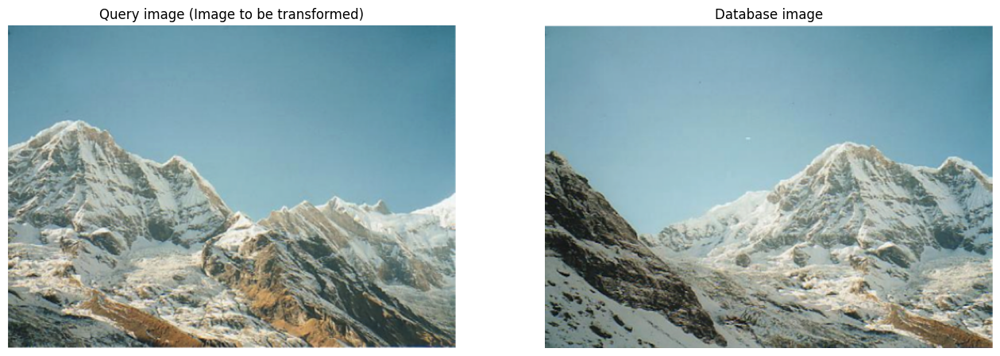

In [ ]:
# Load images
database_image = cv2.imread('mountain1.png')
database_image = cv2.cvtColor(database_image, cv2.COLOR_BGR2RGB)
query_image = cv2.imread('mountain2.png')
query_image = cv2.cvtColor(query_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(16,9))
plt.subplot(1,2,1), plt.imshow(query_image), plt.title("Query image (Image to be transformed)"), plt.axis("off")
plt.subplot(1,2,2), plt.imshow(database_image), plt.title("Database image"), plt.axis("off")
plt.show()

In [ ]:
# Initialize SIFT object
sift = cv2.SIFT_create()

# Get keypoints and descriptors
# SIFT returns a 128-dimensional feature vector for each key point
query_keypoints, query_descriptors = sift.detectAndCompute(query_image, None)
db_keypoints, db_descriptors = sift.detectAndCompute(database_image, None)

print(f"Number of query keypoints: {len(query_keypoints)}")
print(f"Number of database keypoints: {len(db_keypoints)}")

Number of query keypoints: 4623
Number of database keypoints: 4365


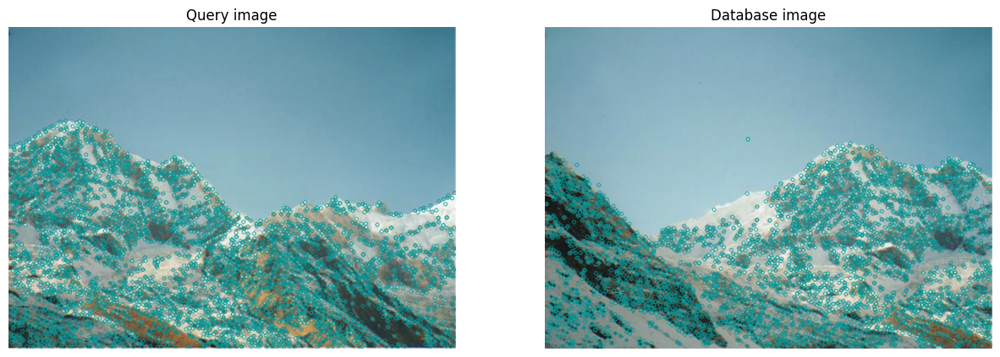

In [ ]:
# display the keypoints detected on both images
plt.figure(figsize=(15,10))
plt.subplot(1,2,1), plt.imshow(cv2.drawKeypoints(query_image, query_keypoints, None, color=(0,150,150))), plt.title('Query image'), plt.axis("off")
plt.subplot(1,2,2), plt.imshow(cv2.drawKeypoints(database_image, db_keypoints, None, color=(0,150,150))), plt.title('Database image'), plt.axis("off")
plt.show()

**Step 2**: Match the descriptors between the two images.

In [ ]:
# Brute-force matcher object
bf = cv2.BFMatcher(cv2.NORM_L2)
# Match descriptors
matches = bf.knnMatch(query_descriptors, db_descriptors, k=2)

# Apply ratio test
matched_des = []
for m_ij, m_ik in matches:
    if m_ij.distance < 0.75 * m_ik.distance:
        matched_des.append(m_ij)

print(f"Number of matches: {len(matched_des)}")

Number of matches: 872


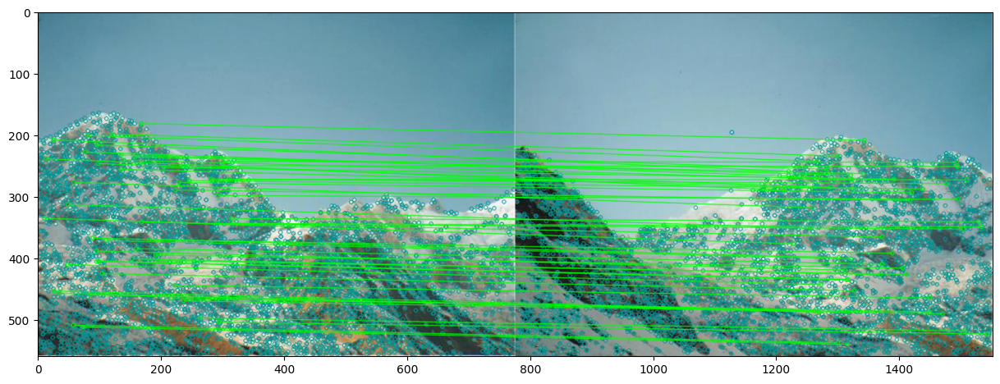

In [ ]:
# Draw 50 random matches
sel_matches = np.random.choice(len(matched_des), 50, replace=False)
matched_des_subset = [matched_des[idx] for idx in sel_matches]

fig = plt.figure(figsize=(15,10))

draw_params = dict(matchColor=(0, 255, 0), singlePointColor=(0, 150, 150), flags=0)
out_matches = cv2.drawMatches(query_image, query_keypoints, database_image, db_keypoints, matched_des_subset,
                           None, **draw_params)
_ = plt.imshow(out_matches)

### **Ex. 2 - Brute-force Matcher with threshold distance**
Use the brute-force matcher to discard all the matches below or above a certain threshold.

In [ ]:
# Get keypoints and descriptors
# SIFT returns a 128-dimensional feature vector for each key point
# YOUR CODE

# Brute-force matcher
# YOUR CODE

# Match descriptors
# YOUR CODE

# Discard matches using the following distance thresholds:
# 1. low threshold: distance below 100
# YOUR CODE

# 2. intermediate threshold: distance below 300
# YOUR CODE

# 3. outliers threshold: distance above 200
# YOUR CODE

#### **Low threshold**
Almost all outliers are excluded from matches.

Number of matches: 75
Minimum distance: 64.73793029785156
Maximum distance: 99.63935089111328


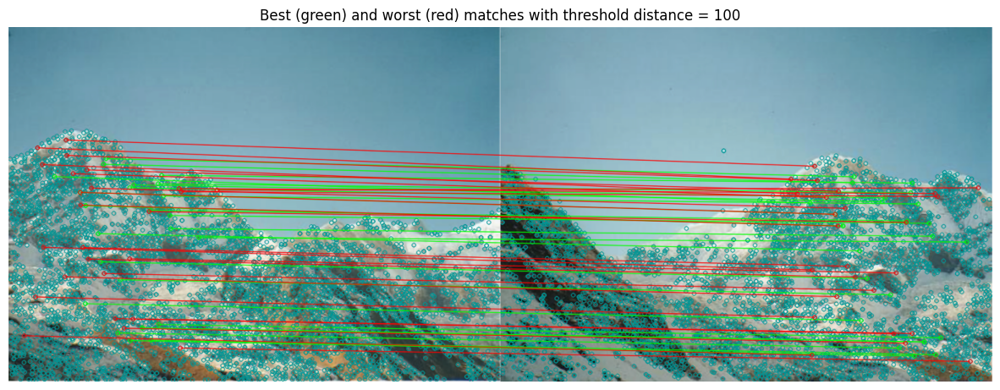

In [ ]:
# Print infos and plot matches
print(f"Number of matches: {len(matched_des)}")
ordered_matches = sorted(matched_des, key=lambda m: m.distance)
print(f"Minimum distance: {ordered_matches[0].distance}")
print(f"Maximum distance: {ordered_matches[-1].distance}")

out_matches = cv2.drawMatches(query_image, query_keypoints, database_image, db_keypoints,
                              ordered_matches[:25], None,
                              matchColor=(0, 255, 0), singlePointColor=(0, 150, 150), flags=0)
out_matches = cv2.drawMatches(query_image, query_keypoints, database_image, db_keypoints,
                              ordered_matches[-25:], out_matches,
                              matchColor=(255, 0, 0),
                              flags=cv2.DrawMatchesFlags_DRAW_OVER_OUTIMG | cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize=(15, 10))
plt.imshow(out_matches), plt.title("Best (green) and worst (red) matches with threshold distance = 100"), plt.axis("off")
plt.show()

**Step 3**: Estimate the homography with RANSAC

In [ ]:
# Location of matches
query_pts = np.zeros((len(matched_des), 2), dtype=np.float32)
db_pts = np.zeros((len(matched_des), 2), dtype=np.float32)

for i, match in enumerate(matched_des):
  query_pts[i, :] = query_keypoints[match.queryIdx].pt
  db_pts[i, :] = db_keypoints[match.trainIdx].pt

# Find homography
H, _ = cv2.findHomography(query_pts, db_pts, cv2.RANSAC)
print(H)

[[ 5.85875823e-01  1.35287048e-01  3.87417191e+02]
 [-2.88826902e-01  8.60766306e-01  8.08571501e+01]
 [-5.01767621e-04 -6.78943803e-05  1.00000000e+00]]


**Step 4**: Apply a warping transformation using the homography matrix obtained from the previous step.

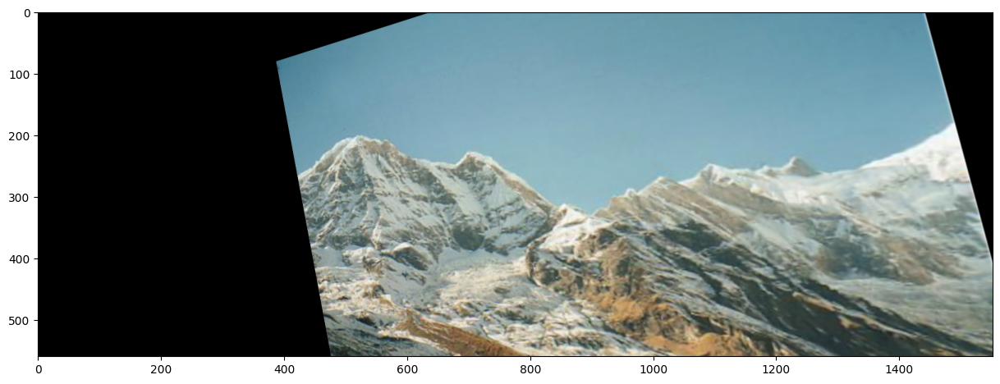

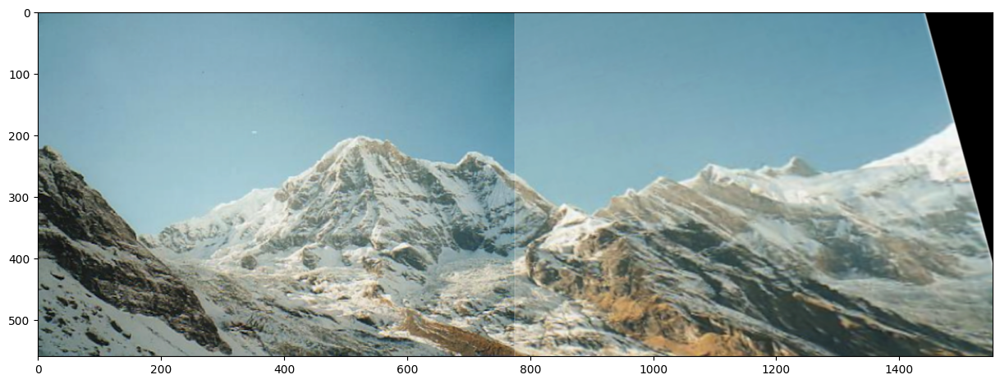

In [ ]:
# Size output image
width = query_image.shape[1] + database_image.shape[1]
height = query_image.shape[0]
# Apply panorama correction
output = cv2.warpPerspective(query_image, H, (width, height))
# Display output
plt.figure(figsize=(15,10))
plt.imshow(output)
plt.show()

output[:database_image.shape[0], :database_image.shape[1], :] = database_image
# Display output
plt.figure(figsize=(15,10))
plt.imshow(output)
plt.show()

#### **Intermediate Threshold**
Outliers are more present in the matches, but their ratio over the total number of matches is still low enough to allow RANSAC to estimate the correct homography from the matches.

Number of matches: 2799
Minimum distance: 64.73793029785156
Maximum distance: 299.9916687011719


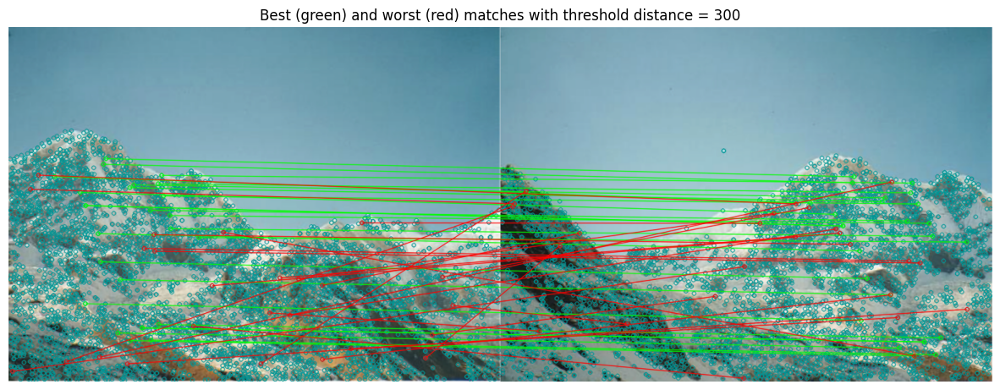

In [ ]:
# Print infos and plot matches
print(f"Number of matches: {len(matched_des_int)}")
ordered_matches_int = sorted(matched_des_int, key=lambda m: m.distance)
print(f"Minimum distance: {ordered_matches_int[0].distance}")
print(f"Maximum distance: {ordered_matches_int[-1].distance}")

out_matches = cv2.drawMatches(query_image, query_keypoints, database_image, db_keypoints,
                              ordered_matches_int[:25], None,
                              matchColor=(0, 255, 0), singlePointColor=(0, 150, 150), flags=0)
out_matches = cv2.drawMatches(query_image, query_keypoints, database_image, db_keypoints,
                              ordered_matches_int[-25:], out_matches,
                              matchColor=(255, 0, 0),
                              flags=cv2.DrawMatchesFlags_DRAW_OVER_OUTIMG | cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize=(15, 10))
plt.imshow(out_matches), plt.title("Best (green) and worst (red) matches with threshold distance = 300"), plt.axis("off")
plt.show()

In [ ]:
# Location of matches
query_pts = np.zeros((len(matched_des_int), 2), dtype=np.float32)
db_pts = np.zeros((len(matched_des_int), 2), dtype=np.float32)

for i, match in enumerate(matched_des_int):
  query_pts[i, :] = query_keypoints[match.queryIdx].pt
  db_pts[i, :] = db_keypoints[match.trainIdx].pt

# Find homography
H, _ = cv2.findHomography(query_pts, db_pts, cv2.RANSAC)
print(H)

[[ 6.04806457e-01  1.34203205e-01  3.86859247e+02]
 [-2.78173334e-01  8.62663250e-01  7.97675790e+01]
 [-4.71734783e-04 -7.19123313e-05  1.00000000e+00]]


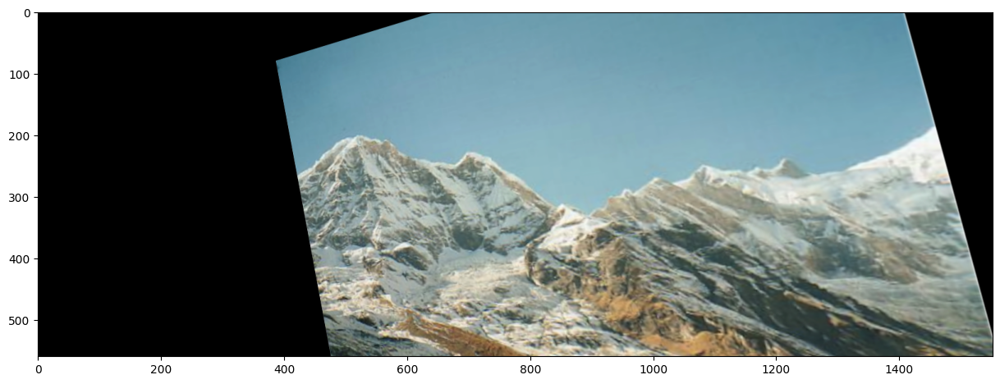

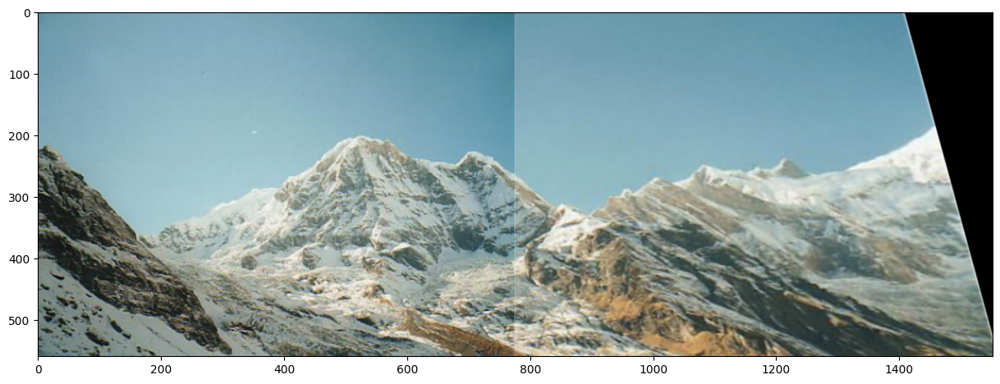

In [ ]:
# Size output image
width = query_image.shape[1] + database_image.shape[1]
height = query_image.shape[0]
# Apply panorama correction
output = cv2.warpPerspective(query_image, H, (width, height))
# Display output
plt.figure(figsize=(15,10))
plt.imshow(output)
plt.show()

output[:database_image.shape[0], :database_image.shape[1], :] = database_image
# Display output
plt.figure(figsize=(15,10))
plt.imshow(output)
plt.show()

#### **Outliers**
When outliers increase, RANSAC starts failing.

Number of matches: 3854
Minimum distance: 200.052490234375
Maximum distance: 405.0839538574219


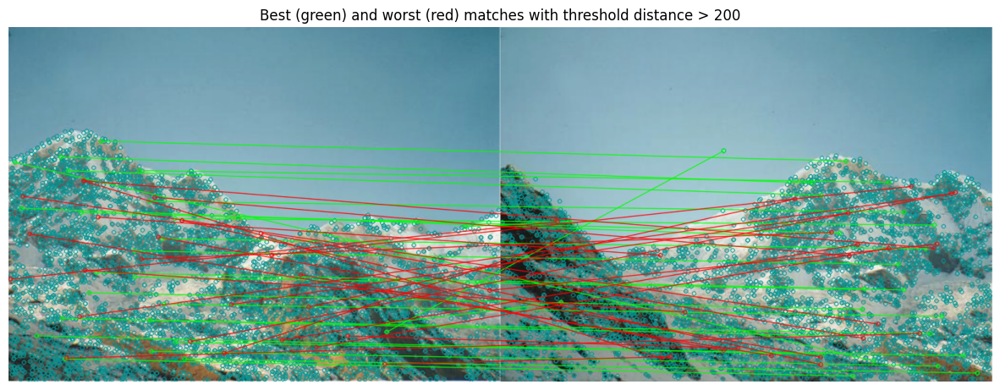

In [ ]:
# Print infos and plot matches
print(f"Number of matches: {len(matched_des_out)}")
ordered_matches_out = sorted(matched_des_out, key=lambda m: m.distance)
print(f"Minimum distance: {ordered_matches_out[0].distance}")
print(f"Maximum distance: {ordered_matches_out[-1].distance}")

out_matches = cv2.drawMatches(query_image, query_keypoints, database_image, db_keypoints,
                              ordered_matches_out[:25], None,
                              matchColor=(0, 255, 0), singlePointColor=(0, 150, 150), flags=0)
out_matches = cv2.drawMatches(query_image, query_keypoints, database_image, db_keypoints,
                              ordered_matches_out[-25:], out_matches,
                              matchColor=(255, 0, 0),
                              flags=cv2.DrawMatchesFlags_DRAW_OVER_OUTIMG | cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize=(15, 10))
plt.imshow(out_matches), plt.title("Best (green) and worst (red) matches with threshold distance > 200"), plt.axis("off")
plt.show()

In [ ]:
# Location of matches
query_pts = np.zeros((len(matched_des_out), 2), dtype=np.float32)
db_pts = np.zeros((len(matched_des_out), 2), dtype=np.float32)

for i, match in enumerate(matched_des_out):
  query_pts[i, :] = query_keypoints[match.queryIdx].pt
  db_pts[i, :] = db_keypoints[match.trainIdx].pt

# Find homography
H, _ = cv2.findHomography(query_pts, db_pts, cv2.RANSAC)
print(H)

[[ 3.26736569e+00  7.58705666e-01  2.20653854e+02]
 [ 1.26110743e+00  1.83878545e+00 -1.87064480e+02]
 [ 2.42022599e-03  8.56000890e-04  1.00000000e+00]]


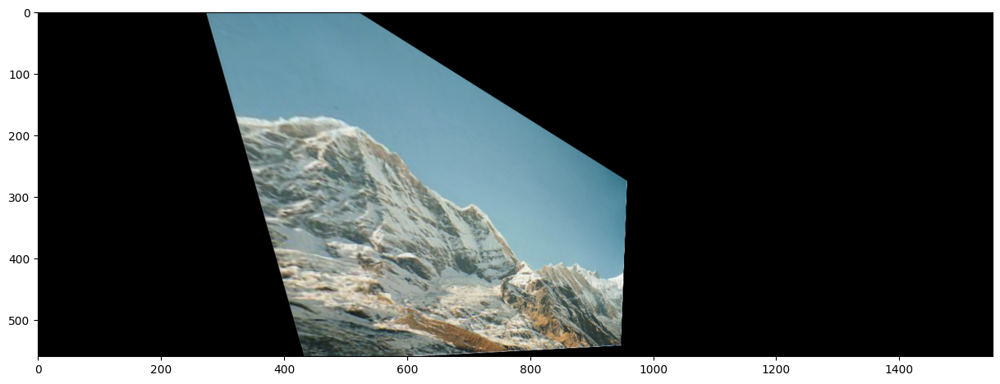

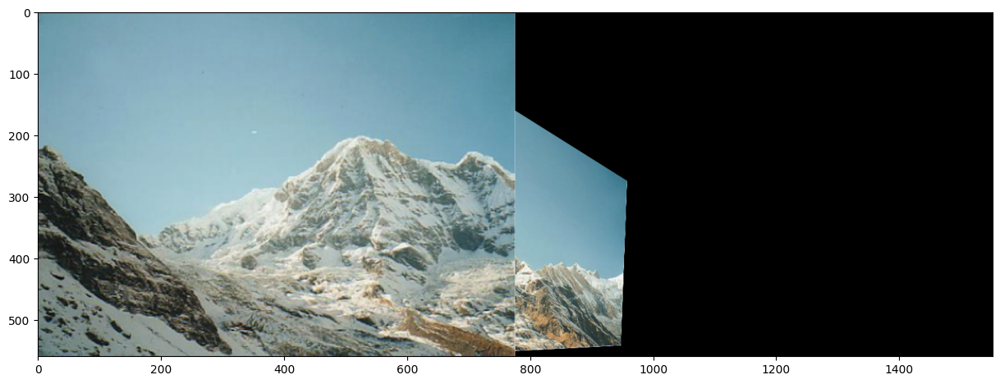

In [ ]:
# Size output image
width = query_image.shape[1] + database_image.shape[1]
height = query_image.shape[0]
# Apply panorama correction
output = cv2.warpPerspective(query_image, H, (width, height))
# Display output
plt.figure(figsize=(15,10))
plt.imshow(output)
plt.show()

output[:database_image.shape[0], :database_image.shape[1], :] = database_image
# Display output
plt.figure(figsize=(15,10))
plt.imshow(output)
plt.show()

*   OpenCV provides the "Stitcher_create()" method for stitching two or more images together.

In [ ]:
# Read images
img1 = cv2.imread("mountain1.png")
img2 = cv2.imread("mountain2.png")

In [ ]:
# Create stitcher object
stitcher = cv2.Stitcher_create()
# Apply stitching
result, img = stitcher.stitch((img1, img2))
assert result == cv2.Stitcher_OK

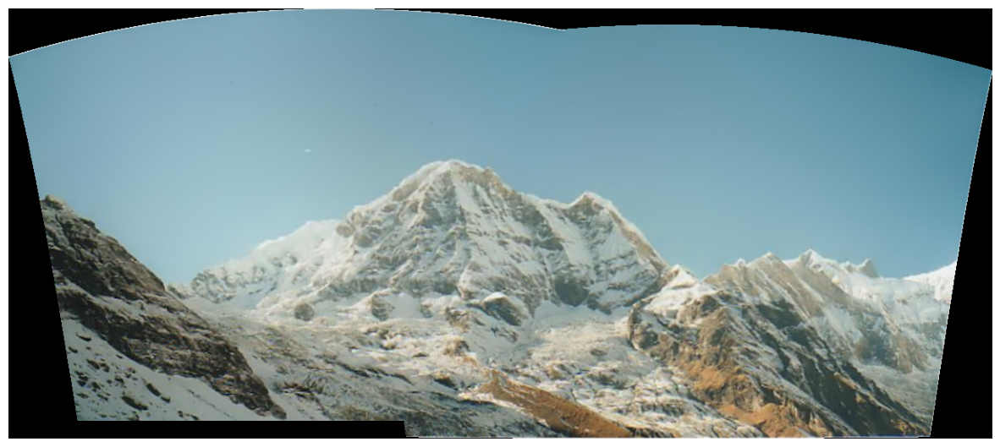

In [ ]:
plt.figure(figsize=(15,8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.axis('off')
plt.show()